# EDA: Folketinget and the European Parliament

This notebook describes the two vote corpora behind the DK–EP comparison. The embedding notebook (`Embeddings_DK_EP.ipynb`) asks whether titles sit near each other in vector space. The prior question is whether a row in each file is the same kind of object, in the same years.

Three facts shape that comparison:

1. The Danish file used for translation and embeddings is one narrow slice of Folketinget roll calls: the third reading of a bill, from September 2014 onward.
2. The European files change meaning in 2019. Folders `2009-2014` and `2014-2019` are every VoteWatch roll-call vote. Folders `2019-2024` and `2024-2029` are main votes only.
3. A Danish title is a full bill title. An EP `display_title` is a short label.

Run this notebook with the working directory set to `notebooks/` or the project root.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CWD = Path.cwd()
if (CWD / "EP").exists():
    PROJECT_DIR = CWD
elif (CWD.parent / "EP").exists():
    PROJECT_DIR = CWD.parent
else:
    raise FileNotFoundError(f"Cannot find the project root from {CWD}")

DK_PATH = PROJECT_DIR / "data" / "temp_data" / "parliament" / "roll_calls_translated.csv"
SAGSOMRAADE_PATH = PROJECT_DIR / "data" / "temp_data" / "parliament" / "dk_sagsomraade.csv"
STEMME_PATH = PROJECT_DIR / "data" / "temp_data" / "parliament" / "stemme.csv"
EP_DATA_DIR = PROJECT_DIR / "EP" / "EP-data"
RAW_DIR = PROJECT_DIR / "data" / "Raw"
EP_PERIODS = ["2009-2014", "2014-2019", "2019-2024", "2024-2029"]

# Constitutive dates of the four EP terms covered by the files.
EP_TERM_BINS = [
    pd.Timestamp("2009-07-14"),
    pd.Timestamp("2014-07-01"),
    pd.Timestamp("2019-07-02"),
    pd.Timestamp("2024-07-16"),
    pd.Timestamp("2029-07-01"),
]
EP_TERM_LABELS = [
    "EP7 2009–2014",
    "EP8 2014–2019",
    "EP9 2019–2024",
    "EP10 2024–2029",
]
# Danish general elections that bound the Folketing files.
FT_TERM_BINS = [
    pd.Timestamp("2011-09-15"),
    pd.Timestamp("2015-06-18"),
    pd.Timestamp("2019-06-05"),
    pd.Timestamp("2022-11-01"),
    pd.Timestamp("2026-12-31"),
]
FT_TERM_LABELS = ["FT 2011–2015", "FT 2015–2019", "FT 2019–2022", "FT 2022–"]

DK_COLOR = "#C60C30"
EP_VOTEWATCH = "#003399"
EP_MAIN = "#7FA0D4"
STEMME_LABELS = {
    1: "For",
    2: "Imod",
    3: "Fravær",
    4: "Hverken for eller imod",
}
GROUP_SHORT = {
    "Group of the Progressive Alliance of Socialists and Democrats in the European Parliament": "S&D",
    "Group of the Alliance of Liberals and Democrats for Europe": "ALDE",
    "Confederal Group of the European United Left - Nordic Green Left": "The Left",
    "Group of the Greens/European Free Alliance": "Greens/EFA",
    "Group of the European People's Party (Christian Democrats)": "EPP",
    "Europe of freedom and democracy Group": "EFD",
    "European Conservatives and Reformists Group": "ECR",
    "Non-attached Members": "NI",
}
GROUP_ORDER = [
    "The Left",
    "Greens/EFA",
    "S&D",
    "ALDE",
    "Renew",
    "EPP",
    "ECR",
    "EFD",
    "Identity and Democracy",
    "PfE",
    "NI",
]
PROCEDURE_LABELS = {
    "COD": "COD ordinary legislative",
    "INI": "INI own-initiative",
    "RSP": "RSP resolution",
    "DEC": "DEC discharge",
    "NLE": "NLE non-legislative",
    "BUD": "BUD budget",
    "INL": "INL legislative initiative",
    "CNS": "CNS consultation",
    "BUI": "BUI budget",
}

plt.rcParams.update({
    "figure.figsize": (10, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
})
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 120)


## 1. Load the files that the comparison actually uses

The Danish side is `roll_calls_translated.csv`: bills (`sagstypeid` 3, case numbers starting with `L`), third reading (`sagstrintypeid` 17), vote type 1. That filter is inherited from the earlier Folketing extract. The European side is `ep_votes.csv` in each term folder, plus Danish MEP lists and their ballots.


In [2]:
df_dk = pd.read_csv(DK_PATH)
df_dk["dato"] = pd.to_datetime(df_dk["dato"])
df_dk["year"] = df_dk["dato"].dt.year
df_dk["title_len_da"] = df_dk["sag_titel"].astype(str).str.len()
df_dk["title_len_en"] = df_dk["sag_titel_en"].astype(str).str.len()
df_dk["bill_prefix"] = df_dk["sag_nummer"].astype(str).str.extract(r"^([A-Za-z]+)", expand=False)
df_dk["ep_term"] = pd.cut(
    df_dk["dato"], bins=EP_TERM_BINS, labels=EP_TERM_LABELS, right=False
)
df_dk["ft_term"] = pd.cut(
    df_dk["dato"], bins=FT_TERM_BINS, labels=FT_TERM_LABELS, right=False
)

print(f"DK rows: {len(df_dk):,}")
print(f"Dates: {df_dk['dato'].min():%Y-%m-%d} → {df_dk['dato'].max():%Y-%m-%d}")
print("Bill-number prefix:", df_dk["bill_prefix"].value_counts().to_dict())
print(
    "Constant ids:",
    {
        "afstemningstypeid": df_dk["afstemningstypeid"].unique().tolist(),
        "sagstypeid": df_dk["sagstypeid"].unique().tolist(),
        "sagstrintypeid": df_dk["sagstrintypeid"].unique().tolist(),
    },
)
print("Unique votes / cases:", df_dk["afstemningid"].nunique(), df_dk["sagid"].nunique())
print("Missing English titles:", int(df_dk["sag_titel_en"].isna().sum()))


DK rows: 2,128
Dates: 2014-09-09 → 2026-08-27
Bill-number prefix: {'L': 2128}
Constant ids: {'afstemningstypeid': [1], 'sagstypeid': [3], 'sagstrintypeid': [17]}
Unique votes / cases: 2128 2128
Missing English titles: 0


In [3]:
ep_frames = []
for period in EP_PERIODS:
    path = EP_DATA_DIR / period / "ep_votes.csv"
    frame = pd.read_csv(path)
    frame["period_folder"] = period
    frame["source_family"] = (
        "VoteWatch, all roll calls"
        if period in {"2009-2014", "2014-2019"}
        else "Main votes"
    )
    ep_frames.append(frame)

df_ep = pd.concat(ep_frames, ignore_index=True)
df_ep["timestamp"] = pd.to_datetime(
    df_ep["timestamp"], format="ISO8601", utc=True, errors="coerce"
).dt.tz_convert(None)
df_ep["year"] = df_ep["timestamp"].dt.year
df_ep["title_len"] = df_ep["display_title"].str.len()
df_ep["ep_term"] = pd.cut(
    df_ep["timestamp"], bins=EP_TERM_BINS, labels=EP_TERM_LABELS, right=False
)
if "is_main" not in df_ep.columns:
    df_ep["is_main"] = pd.NA

print(f"EP rows: {len(df_ep):,}")
print(f"Unparsed timestamps: {int(df_ep['timestamp'].isna().sum())}")
print(f"Missing display titles: {int(df_ep['display_title'].isna().sum())}")
for period, part in df_ep.groupby("period_folder", sort=False):
    has_main = part["is_main"].notna().any()
    main_note = (
        part["is_main"].value_counts(dropna=False).to_dict() if has_main else "column absent"
    )
    print(
        f"{period}: {len(part):,} votes, "
        f"{part['timestamp'].min():%Y-%m-%d} → {part['timestamp'].max():%Y-%m-%d}, "
        f"is_main={main_note}"
    )


EP rows: 19,635
Unparsed timestamps: 0
Missing display titles: 1
2009-2014: 6,961 votes, 2009-09-14 → 2014-04-17, is_main=column absent
2014-2019: 10,252 votes, 2014-07-16 → 2019-12-03, is_main=column absent
2019-2024: 1,808 votes, 2019-07-18 → 2024-04-25, is_main={True: 1808}
2024-2029: 614 votes, 2024-07-17 → 2026-07-09, is_main={True: 614}


In [4]:
df_so = pd.read_csv(SAGSOMRAADE_PATH)
df_stemme = pd.read_csv(STEMME_PATH, usecols=["afstemningid", "aktørid", "typeid"])
df_stemme["position"] = df_stemme["typeid"].map(STEMME_LABELS)

raw_frames = []
for path in sorted(RAW_DIR.glob("P*_DK.csv")):
    part = pd.read_csv(path, usecols=["afstemningid", "aktørid", "party", "dato"])
    part["folketing_file"] = path.stem
    raw_frames.append(part)
df_raw = pd.concat(raw_frames, ignore_index=True)
df_raw["dato"] = pd.to_datetime(df_raw["dato"])

print(f"Sagsområder: {len(df_so):,} rows, {df_so['sagid'].nunique():,} cases, {df_so['emneord'].nunique():,} labels")
print(f"Stemme rows: {len(df_stemme):,} on {df_stemme['afstemningid'].nunique():,} votes")
print(f"Party-file rows: {len(df_raw):,} on {df_raw['afstemningid'].nunique():,} votes")


Sagsområder: 2,261 rows, 2,105 cases, 253 labels
Stemme rows: 363,623 on 2,031 votes
Party-file rows: 1,026,339 on 9,870 votes


## 2. Inventory

Each Danish row is one third-reading vote on one bill. Each European row is one roll-call vote, and the 2019 change of source is a change of which roll calls are kept.


In [5]:
inventory = pd.DataFrame(
    [
        {
            "corpus": "Folketinget",
            "rows": len(df_dk),
            "first": df_dk["dato"].min().date().isoformat(),
            "last": df_dk["dato"].max().date().isoformat(),
            "text_field": "sag_titel_en",
            "median_title_chars": int(df_dk["title_len_en"].median()),
            "unit": "third reading of one bill (L)",
        },
        {
            "corpus": "European Parliament",
            "rows": len(df_ep),
            "first": df_ep["timestamp"].min().date().isoformat(),
            "last": df_ep["timestamp"].max().date().isoformat(),
            "text_field": "display_title",
            "median_title_chars": int(df_ep["title_len"].median()),
            "unit": "roll call; main votes only in the 2019–2024 and 2024–2029 folders",
        },
    ]
)
inventory


,corpus,rows,first,last,text_field,median_title_chars,unit
0,Folketinget,2128,2014-09-09,2026-08-27,sag_titel_en,148,third reading of one bill (L)
1,European Parliament,19635,2009-09-14,2026-07-09,display_title,60,roll call; main votes only in the 2019–2024 and 2024–2029 folders


In [6]:
term_summary = (
    df_ep.groupby(["period_folder", "source_family"], sort=False)
    .agg(
        votes=("id", "size"),
        first=("timestamp", "min"),
        last=("timestamp", "max"),
        procedures=("procedure_reference", "nunique"),
        empty_titles=("display_title", lambda s: int(s.isna().sum())),
    )
    .reset_index()
)
term_summary["first"] = term_summary["first"].dt.date
term_summary["last"] = term_summary["last"].dt.date
term_summary


,period_folder,source_family,votes,first,last,procedures,empty_titles
0,2009-2014,"VoteWatch, all roll calls",6961,2009-09-14,2014-04-17,12,0
1,2014-2019,"VoteWatch, all roll calls",10252,2014-07-16,2019-12-03,10,0
2,2019-2024,Main votes,1808,2019-07-18,2024-04-25,1604,1
3,2024-2029,Main votes,614,2024-07-17,2026-07-09,529,0


## 3. Why the EP counts fall after 2018

VoteWatch years contain on the order of 1,000–2,300 roll calls. From the 2019–2024 folder onward the files contain a few hundred main votes a year. Danish third readings stay near 150–260 a year across the whole series, so they sit on the same scale as the later EP files and far below the VoteWatch files. On the shared scale the Danish bars are the short red marks. 2026 is a partial year: the Folketing file ends on 27 August and the EP file on 9 July.

The `is_main` flag does not create this cliff. In the two later folders every row is already `is_main=True`. The earlier folders have no `is_main` column because they were exported as the full roll-call record.


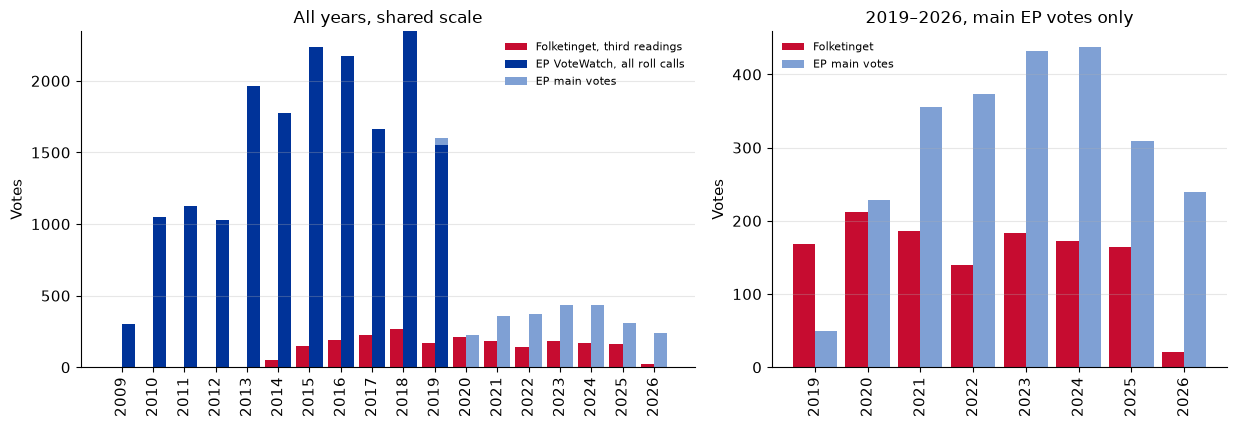

,dk_third_readings,ep_votewatch,ep_main
year,,,
2014,54,1777,0
2015,152,2238,0
2016,188,2172,0
2017,222,1663,0
2018,264,2346,0
2019,169,1551,49
2020,212,0,228
2021,186,0,355
2022,140,0,373


In [7]:
years = list(range(2009, 2027))
ep_year = (
    df_ep.dropna(subset=["year"])
    .groupby(["year", "source_family"])
    .size()
    .unstack(fill_value=0)
    .reindex(years, fill_value=0)
)
dk_year = df_dk.groupby("year").size().reindex(years, fill_value=0)
vw_col = "VoteWatch, all roll calls"
main_col = "Main votes"

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.35, 1]})

ax = axes[0]
x = np.arange(len(years))
width = 0.42
ax.bar(x - width / 2, dk_year.to_numpy(), width, color=DK_COLOR, label="Folketinget, third readings")
ax.bar(x + width / 2, ep_year[vw_col].to_numpy(), width, color=EP_VOTEWATCH, label="EP VoteWatch, all roll calls")
ax.bar(
    x + width / 2,
    ep_year[main_col].to_numpy(),
    width,
    bottom=ep_year[vw_col].to_numpy(),
    color=EP_MAIN,
    label="EP main votes",
)
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=90)
ax.set_ylabel("Votes")
ax.set_title("All years, shared scale")
ax.legend(frameon=False, fontsize=8)

overlap_years = list(range(2019, 2027))
ax = axes[1]
x2 = np.arange(len(overlap_years))
dk_overlap = dk_year.loc[overlap_years]
ep_overlap = ep_year.loc[overlap_years, main_col]
ax.bar(x2 - width / 2, dk_overlap.to_numpy(), width, color=DK_COLOR, label="Folketinget")
ax.bar(x2 + width / 2, ep_overlap.to_numpy(), width, color=EP_MAIN, label="EP main votes")
ax.set_xticks(x2)
ax.set_xticklabels(overlap_years, rotation=90)
ax.set_ylabel("Votes")
ax.set_title("2019–2026, main EP votes only")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

annual = pd.DataFrame({"dk_third_readings": dk_year, "ep_votewatch": ep_year[vw_col], "ep_main": ep_year[main_col]})
annual.loc[2014:2026]


## 4. Periods: folder name, EP term, Folketing term

Meeting notes asked whether periods should follow the European Parliament or the Folketing. The folder name is a weak definition. Assigning each vote by its date to the EP term (constitutive session to the next) shows that the `2014-2019` folder continues after the 2 July 2019 opening of EP9.

The Danish comparison file starts on 9 September 2014, so it shares no months with EP7. Overlap begins in EP8.


In [8]:
folder_vs_term = pd.crosstab(
    df_ep["period_folder"],
    df_ep["ep_term"].astype(str),
    dropna=False,
)
folder_vs_term = folder_vs_term.reindex(index=EP_PERIODS, columns=EP_TERM_LABELS).fillna(0).astype(int)
print("EP votes by folder and by date-based term")
display(folder_vs_term)

dk_start = df_dk["dato"].min()
dk_end = df_dk["dato"].max()
ep_in_dk_window = df_ep["timestamp"].between(dk_start, dk_end)
coverage = (
    df_ep.assign(in_dk_window=ep_in_dk_window)
    .groupby("ep_term", observed=False)
    .agg(ep_votes=("id", "size"), ep_votes_inside_dk_dates=("in_dk_window", "sum"))
)
coverage["dk_third_readings"] = df_dk.groupby("ep_term", observed=False).size()
coverage = coverage.reindex(EP_TERM_LABELS).fillna(0).astype(int)
print("Votes inside each EP term. DK dates run", f"{dk_start:%Y-%m-%d} → {dk_end:%Y-%m-%d}")
coverage


EP votes by folder and by date-based term


ep_term,EP7 2009–2014,EP8 2014–2019,EP9 2019–2024,EP10 2024–2029
period_folder,,,,
2009-2014,6961,0,0,0
2014-2019,0,10094,158,0
2019-2024,0,0,1808,0
2024-2029,0,0,0,614


Votes inside each EP term. DK dates run 2014-09-09 → 2026-08-27


,ep_votes,ep_votes_inside_dk_dates,dk_third_readings
ep_term,,,
EP7 2009–2014,6961,0,0
EP8 2014–2019,10094,10055,976
EP9 2019–2024,1966,1966,895
EP10 2024–2029,614,614,257


In [9]:
ft_counts = df_dk.groupby("ft_term", observed=False).size().rename("dk_third_readings")
print("Danish third readings by Folketing term (election to election)")
ft_counts.to_frame()


Danish third readings by Folketing term (election to election)


,dk_third_readings
ft_term,
FT 2011–2015,143
FT 2015–2019,833
FT 2019–2022,599
FT 2022–,553


## 5. What one row refers to

On the Danish side, votes and cases are the same count: one retained roll call per bill.

On the European side the identifier `procedure_reference` means two different things. In the VoteWatch folders it is empty on most rows. Where it is filled in, the values are stage marks such as `***I` or `***II`, naming the reading rather than the dossier. In the later folders it is a dossier id, and most dossiers contribute one main vote. Category columns also change codebook: `vote_type` in the early files, `procedure_type` in the later files. The VoteWatch export spells the same resolution label in several ways (`Motion for resolution` and `Motion for a resolution`); the chart below joins those spelling variants.


In [10]:
print("DK votes per case:", int(df_dk.groupby("sagid").size().max()))

old = df_ep[df_ep["source_family"] == "VoteWatch, all roll calls"].copy()
new = df_ep[df_ep["source_family"] == "Main votes"].copy()
print(
    "VoteWatch rows with an empty procedure_reference:",
    f"{old['procedure_reference'].isna().mean():.1%}",
)
old_ref = (
    old["procedure_reference"]
    .dropna()
    .astype(str)
    .str.replace(r"\s+", "", regex=True)
)
print("Non-empty VoteWatch procedure_reference values, whitespace removed:")
display(old_ref.value_counts().rename("votes").to_frame())

per_dossier = new.groupby("procedure_reference").size()
print("Main-vote files: votes per procedure_reference")
display(per_dossier.describe().to_frame("votes_per_procedure"))
print("Share of dossiers with exactly one main vote:", f"{(per_dossier == 1).mean():.1%}")


DK votes per case: 1
VoteWatch rows with an empty procedure_reference: 73.8%
Non-empty VoteWatch procedure_reference values, whitespace removed:


,votes
procedure_reference,
***I,3419
*,616
***,315
***II,145
***III,8


Main-vote files: votes per procedure_reference


,votes_per_procedure
count,2123.000000
mean,1.112106
std,0.369246
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,5.000000


Share of dossiers with exactly one main vote: 90.2%


Raw vote_type labels: 39; after spelling cleanup: 32


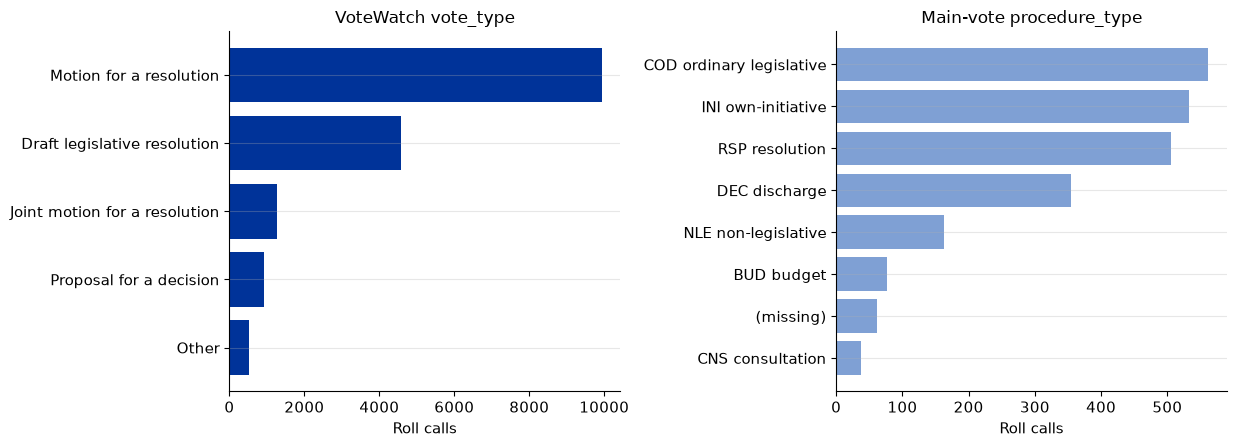

In [11]:
VOTE_TYPE_ALIASES = {
    "motion for resolution": "motion for a resolution",
    "motions for a resolution": "motion for a resolution",
    "joint motion for resolution": "joint motion for a resolution",
    "joint motions for a resolution": "joint motion for a resolution",
}

def canonical_vote_type(value):
    if pd.isna(value):
        return "(missing)"
    raw = " ".join(str(value).split())
    key = raw.casefold().replace("recomandation", "recommendation")
    mapped = VOTE_TYPE_ALIASES.get(key)
    if mapped:
        return mapped[:1].upper() + mapped[1:]
    return raw

vote_type = old["vote_type"].map(canonical_vote_type).value_counts()
print(f"Raw vote_type labels: {old['vote_type'].nunique(dropna=False):,}; after spelling cleanup: {vote_type.size:,}")
vote_type_plot = vote_type.head(4)
if len(vote_type) > 4:
    vote_type_plot.loc["Other"] = int(vote_type.iloc[4:].sum())

proc = new["procedure_type"].fillna("(missing)")
proc_counts = proc.value_counts()
proc_plot = proc_counts.head(8).rename(index=lambda k: PROCEDURE_LABELS.get(k, k))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].barh(vote_type_plot.index[::-1], vote_type_plot.to_numpy()[::-1], color=EP_VOTEWATCH)
axes[0].set_title("VoteWatch vote_type")
axes[0].set_xlabel("Roll calls")
axes[1].barh(proc_plot.index[::-1], proc_plot.to_numpy()[::-1], color=EP_MAIN)
axes[1].set_title("Main-vote procedure_type")
axes[1].set_xlabel("Roll calls")
fig.tight_layout()
plt.show()


## 6. Titles

English bill titles are several times longer than EP display titles. The median Danish English title is a full sentence naming the law being amended. The median EP title is a short label, and the same label is reused across thousands of roll calls.

The Danish English titles are not unique either. The translation often keeps the name of the law and drops the parenthesis that says what the amendment changes, so different bills share one English string.


Title length, characters


,DK Danish title,DK English title,EP display title
count,2128.0,2128.0,19634.0
mean,193.5,179.7,68.3
std,113.1,138.8,39.5
min,20.0,18.0,4.0
25%,113.0,87.0,44.0
50%,170.5,148.0,60.0
75%,252.0,236.0,83.0
max,872.0,1913.0,965.0


DK English titles longer than 400 characters: 114
EP titles longer than 400 characters: 12
Duplicate DK English titles: 129
Duplicate EP display titles: 13381


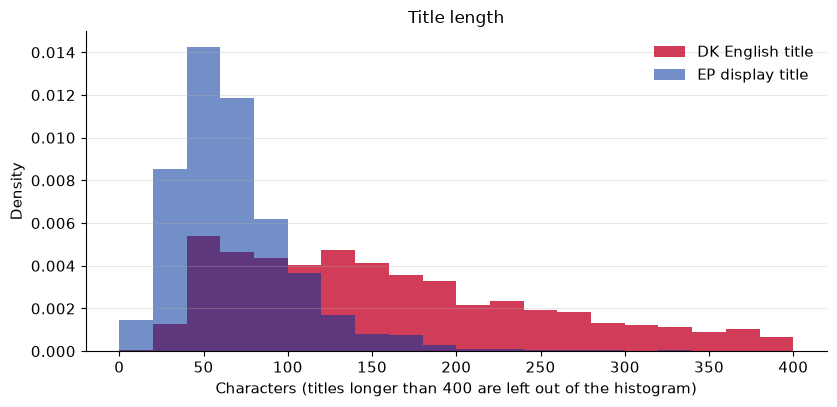

English titles used more than once: 54, covering 183 bills. 43 of those titles stand in for Danish originals that differ.
Example of one English title on different bills:


,dato,sag_nummer,sag_titel,sag_titel_en
0,2015-12-21,L 47,Forslag til lov om ændring af lov om social service. (Målretning af de forebyggende hjemmebesøg).,Proposal for a law amending the Social Services Act.
1,2016-02-23,L 105,Forslag til lov om ændring af lov om social service. (Værdighedspolitikker for ældreplejen).,Proposal for a law amending the Social Services Act.
2,2018-03-15,L 119,"Forslag til lov om ændring af lov om social service. (Mulighed for forbud mod enheder, der muliggør intern...",Proposal for a law amending the Social Services Act.


In [12]:
print("Title length, characters")
length_summary = pd.DataFrame({
    "DK Danish title": df_dk["title_len_da"].describe(),
    "DK English title": df_dk["title_len_en"].describe(),
    "EP display title": df_ep["title_len"].describe(),
}).round(1)
display(length_summary)
print("DK English titles longer than 400 characters:", int((df_dk["title_len_en"] > 400).sum()))
print("EP titles longer than 400 characters:", int((df_ep["title_len"] > 400).sum()))
print("Duplicate DK English titles:", int(df_dk["sag_titel_en"].duplicated().sum()))
print("Duplicate EP display titles:", int(df_ep["display_title"].duplicated().sum()))

bins = np.arange(0, 420, 20)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(
    df_dk.loc[df_dk["title_len_en"] <= 400, "title_len_en"],
    bins=bins,
    density=True,
    color=DK_COLOR,
    alpha=0.8,
    label="DK English title",
)
ax.hist(
    df_ep.loc[df_ep["title_len"] <= 400, "title_len"],
    bins=bins,
    density=True,
    color=EP_VOTEWATCH,
    alpha=0.55,
    label="EP display title",
)
ax.set_xlabel("Characters (titles longer than 400 are left out of the histogram)")
ax.set_ylabel("Density")
ax.set_title("Title length")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

shared = df_dk[df_dk["sag_titel_en"].duplicated(keep=False)]
groups = shared.groupby("sag_titel_en")["sag_titel"].nunique()
print(
    f"English titles used more than once: {groups.size:,}, "
    f"covering {len(shared):,} bills. "
    f"{int((groups > 1).sum()):,} of those titles stand in for Danish originals that differ."
)
example_title = groups[groups > 1].sort_values(ascending=False).index[0]
example = (
    df_dk.loc[df_dk["sag_titel_en"].eq(example_title), ["dato", "sag_nummer", "sag_titel", "sag_titel_en"]]
    .sort_values("dato")
    .head(3)
    .copy()
)
example["dato"] = example["dato"].dt.date
print("Example of one English title on different bills:")
display(example.reset_index(drop=True))


In [13]:
sample_year = 2022
rng = np.random.default_rng(42)
dk_sample_idx = rng.choice(df_dk.index[df_dk["year"] == sample_year], size=4, replace=False)
ep_pool = df_ep.index[(df_ep["year"] == sample_year) & df_ep["display_title"].notna()]
ep_sample_idx = rng.choice(ep_pool, size=4, replace=False)

dk_examples = df_dk.loc[dk_sample_idx, ["dato", "sag_nummer", "sag_titel_en"]].copy()
dk_examples["dato"] = dk_examples["dato"].dt.date
ep_examples = df_ep.loc[ep_sample_idx, ["timestamp", "period_folder", "display_title"]].copy()
ep_examples["timestamp"] = ep_examples["timestamp"].dt.date

print(f"Random Danish third readings from {sample_year}")
display(dk_examples.reset_index(drop=True))
print(f"Random EP roll calls from {sample_year}")
display(ep_examples.reset_index(drop=True))


Random Danish third readings from 2022


,dato,sag_nummer,sag_titel_en
0,2022-05-19,L 137,Proposal for a law amending the law on the use of Denmark's underground. (Geological storage of CO2 of les...
1,2022-03-01,L 49,"Proposal for a law amending the law on the rental of general housing, the law on general housing, etc., th..."
2,2022-06-09,L 147 A,Proposal for a law amending the Health Act. (State's Serum Institute's activities in international coopera...
3,2022-06-09,L 162 A,Proposal for a law amending the law on police activities and the law on watchkeeping.


Random EP roll calls from 2022


,timestamp,period_folder,display_title
0,2022-07-07,2019-2024,The situation in Tajikistan’s Gorno-Badakhshan Autonomous Province
1,2022-04-05,2019-2024,Equivalence of field inspections and of certain seed produced in Bolivia
2,2022-02-17,2019-2024,Political crisis in Burkina Faso
3,2022-06-07,2019-2024,The implementation of Article 17 of the Common Fisheries Policy Regulation


## 7. What the Danish bills are about

`dk_sagsomraade.csv` attaches one or more subject labels to almost every bill in the comparison file. The largest labels are domestic (criminal law, schools, tax, energy). A bill can carry the subject `EU`, and a title can mention Europe, but that is a small share of third readings. The EP files have no matching subject vocabulary; `procedure_type` above is a procedure class, not a policy area.


Bills with at least one sagsområde: 98.9% (2,105 of 2,128)
Labels per tagged bill:


,labels
count,2105.000000
mean,1.074109
std,0.291221
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,4.000000


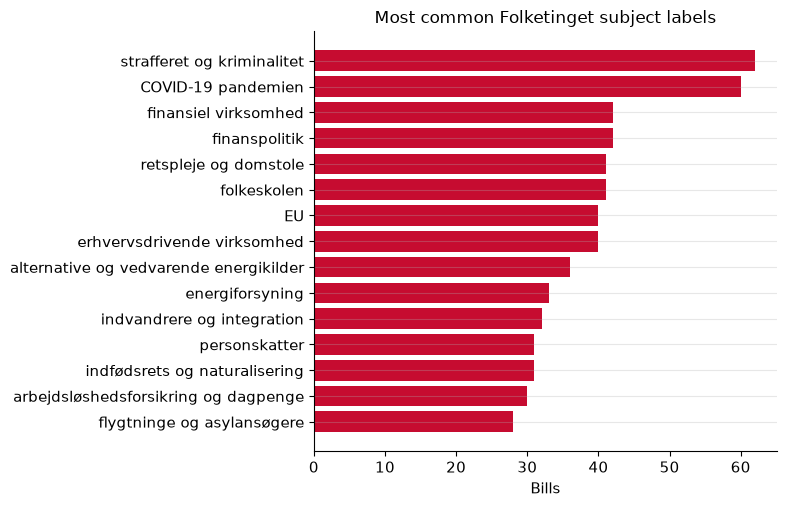

Bills tagged EU: 40


Bills whose Danish title mentions EU or Europa: 80
Tagged EU and title mention: 23


In [14]:
tagged = df_dk["sagid"].isin(set(df_so["sagid"]))
print(f"Bills with at least one sagsområde: {tagged.mean():.1%} ({int(tagged.sum()):,} of {len(df_dk):,})")
print("Labels per tagged bill:")
display(df_so.groupby("sagid").size().describe().to_frame("labels"))

top_subjects = df_so["emneord"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top_subjects.index, top_subjects.to_numpy(), color=DK_COLOR)
ax.set_xlabel("Bills")
ax.set_title("Most common Folketinget subject labels")
fig.tight_layout()
plt.show()

eu_tag_ids = set(df_so.loc[df_so["emneord"].eq("EU"), "sagid"])
title_mentions_eu = df_dk["sag_titel"].str.contains(
    r"(?<![A-Za-zÆØÅæøå])EU(?![A-Za-zÆØÅæøå])|Europa|europæ",
    case=False,
    na=False,
)
print(f"Bills tagged EU: {df_dk['sagid'].isin(eu_tag_ids).sum():,}")
print(f"Bills whose Danish title mentions EU or Europa: {int(title_mentions_eu.sum()):,}")
print(
    "Tagged EU and title mention:",
    int((df_dk["sagid"].isin(eu_tag_ids) & title_mentions_eu).sum()),
)


## 8. Who votes

Danish MEP rolls exist for every term folder. Group names in the VoteWatch files are long labels; later files already use short labels. A few MEPs have two group rows in one term, so the table keeps the latest membership in that file. National party is stored only in the VoteWatch member files.

Individual Folketing ballots live in `stemme.csv`. The project’s existing map is `1` For, `2` Imod, `3` Fravær, `4` Hverken for eller imod. Those margins describe third readings. The MEP margins describe whatever roll calls the EP file kept, so the higher For share from 2019 follows the switch to main votes.

The party column in `data/Raw/P*_DK.csv` is a poor guide to historical blocs. Danmarksdemokraterne and Moderaterne, which entered the Folketing in November 2022, are already attached to votes in the 2011–2015 extract. The chart below is limited to votes from the 2022 election onward, and even there the string is the label stored in the extract.


In [15]:
member_rows = []
multi_group = []
for period in EP_PERIODS:
    members = pd.read_csv(EP_DATA_DIR / period / "ep_members_dk.csv")
    groups = pd.read_csv(EP_DATA_DIR / period / "ep_group_memberships_dk.csv")
    groups["start_date"] = pd.to_datetime(groups["start_date"], errors="coerce")
    n_multi = int((groups.groupby("member_id").size() > 1).sum())
    multi_group.append({"period_folder": period, "meps_with_two_group_rows": n_multi, "meps": len(members)})
    if "ep_group" in members.columns:
        members = members.copy()
        members["group_label"] = members["ep_group"].map(GROUP_SHORT).fillna(members["ep_group"])
        members["national_party"] = members["national_party"]
    else:
        latest = groups.sort_values("start_date").drop_duplicates("member_id", keep="last")
        members = members.merge(
            latest[["member_id", "short_label"]],
            left_on="id",
            right_on="member_id",
            how="left",
        )
        members["group_label"] = members["short_label"]
        members["national_party"] = pd.NA
    members["period_folder"] = period
    member_rows.append(members[["period_folder", "id", "group_label", "national_party"]])

df_meps = pd.concat(member_rows, ignore_index=True)
print("Danish MEPs, and how many have more than one group row in the term file")
display(pd.DataFrame(multi_group))

unmapped = sorted(set(df_meps["group_label"].dropna()) - set(GROUP_ORDER))
if unmapped:
    print("Group labels outside the display order:", unmapped)

group_counts = pd.crosstab(df_meps["period_folder"], df_meps["group_label"])
group_counts = group_counts.reindex(index=EP_PERIODS)
ordered_cols = [c for c in GROUP_ORDER if c in group_counts.columns] + [
    c for c in group_counts.columns if c not in GROUP_ORDER
]
group_counts = group_counts.reindex(columns=ordered_cols).fillna(0).astype(int)
display(group_counts)

national = (
    df_meps.dropna(subset=["national_party"])
    .groupby(["period_folder", "national_party"])
    .size()
    .rename("meps")
    .reset_index()
)
print("National party is stored for the VoteWatch terms only")
display(national.sort_values(["period_folder", "meps"], ascending=[True, False]))


Danish MEPs, and how many have more than one group row in the term file


,period_folder,meps_with_two_group_rows,meps
0,2009-2014,0,15
1,2014-2019,0,14
2,2019-2024,2,17
3,2024-2029,2,16


group_label,The Left,Greens/EFA,S&D,ALDE,Renew,EPP,ECR,EFD,Identity and Democracy,PfE,NI
period_folder,,,,,,,,,,,
2009-2014,2,1,6,3,0,1,1,1,0,0,0
2014-2019,1,1,3,3,0,1,3,0,0,0,1
2019-2024,1,2,3,0,8,1,0,0,2,0,0
2024-2029,1,3,3,0,4,2,1,0,0,2,0


National party is stored for the VoteWatch terms only


,period_folder,national_party,meps
4,2009-2014,Socialdemokratiet,6
6,2009-2014,"Venstre, Danmarks Liberale Parti",3
2,2009-2014,Folkebevægelsen mod EU,2
0,2009-2014,Dansk Folkeparti,1
1,2009-2014,Det Konservative Folkeparti,1
3,2009-2014,Miljøpartiet Fokus,1
5,2009-2014,Socialistisk Folkeparti,1
7,2014-2019,Dansk Folkeparti,3
12,2014-2019,Socialdemokratiet,3
9,2014-2019,Det Radikale Venstre,2


Third readings with individual ballots in stemme.csv: 2,031 of 2,128
Ballots per such vote: 179.0


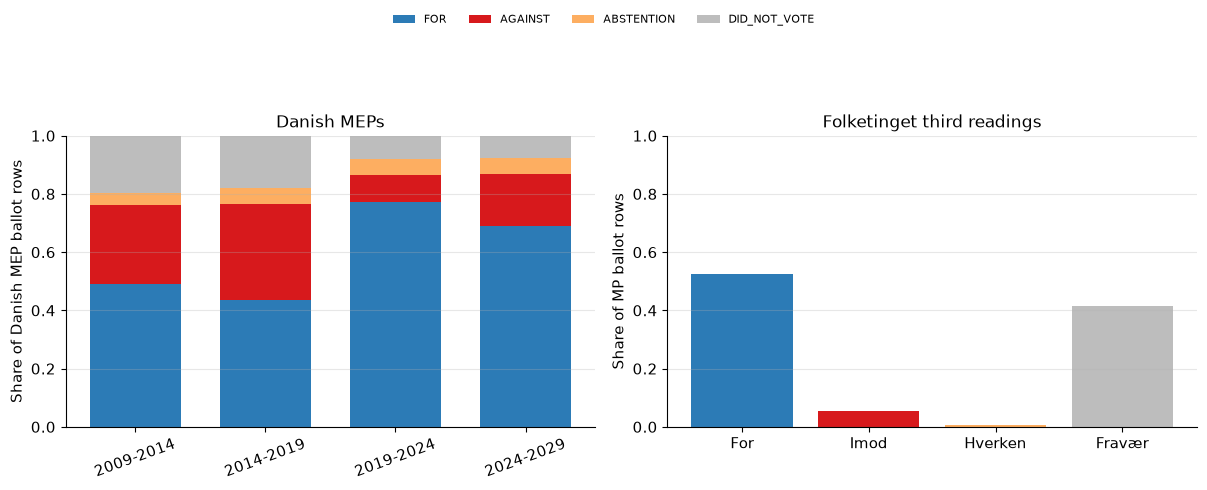

Danish MEP ballot shares


position,FOR,AGAINST,ABSTENTION,DID_NOT_VOTE
period_folder,,,,
2009-2014,0.491,0.270,0.040,0.198
2014-2019,0.436,0.328,0.055,0.180
2019-2024,0.773,0.092,0.056,0.080
2024-2029,0.690,0.180,0.055,0.075


Folketing third-reading ballot shares


,share
position,
For,0.524
Imod,0.054
Hverken for eller imod,0.007
Fravær,0.415


In [16]:
ballot_frames = []
for period in EP_PERIODS:
    ballots = pd.read_csv(
        EP_DATA_DIR / period / "ep_member_votes_dk.csv",
        usecols=["vote_id", "member_id", "position"],
    )
    ballots["period_folder"] = period
    ballot_frames.append(ballots)
df_ballots = pd.concat(ballot_frames, ignore_index=True)

position_order = ["FOR", "AGAINST", "ABSTENTION", "DID_NOT_VOTE"]
position_share = (
    pd.crosstab(df_ballots["period_folder"], df_ballots["position"], normalize="index")
    .reindex(index=EP_PERIODS, columns=position_order)
    .fillna(0)
)

dk_ballots = df_stemme[df_stemme["afstemningid"].isin(set(df_dk["afstemningid"]))].copy()
votes_with_ballots = dk_ballots["afstemningid"].nunique()
print(
    f"Third readings with individual ballots in stemme.csv: "
    f"{votes_with_ballots:,} of {len(df_dk):,}"
)
print(
    "Ballots per such vote:",
    f"{len(dk_ballots) / votes_with_ballots:.1f}",
)
dk_share = dk_ballots["position"].value_counts(normalize=True).rename("share")
dk_share = dk_share.reindex(["For", "Imod", "Hverken for eller imod", "Fravær"]).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
position_colors = {
    "FOR": "#2c7bb6",
    "AGAINST": "#d7191c",
    "ABSTENTION": "#fdae61",
    "DID_NOT_VOTE": "#bdbdbd",
    "For": "#2c7bb6",
    "Imod": "#d7191c",
    "Hverken for eller imod": "#fdae61",
    "Fravær": "#bdbdbd",
}
left = np.zeros(len(position_share))
x = np.arange(len(position_share))
for col in position_order:
    axes[0].bar(x, position_share[col], bottom=left, color=position_colors[col], label=col, width=0.7)
    left = left + position_share[col].to_numpy()
axes[0].set_xticks(x)
axes[0].set_xticklabels(position_share.index, rotation=20)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Share of Danish MEP ballot rows")
axes[0].set_title("Danish MEPs")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12))

dk_tick_labels = ["For", "Imod", "Hverken", "Fravær"]
axes[1].bar(
    dk_tick_labels,
    dk_share.to_numpy(),
    color=[position_colors[i] for i in dk_share.index],
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Share of MP ballot rows")
axes[1].set_title("Folketinget third readings")
fig.tight_layout()
fig.subplots_adjust(top=0.82)
plt.show()

print("Danish MEP ballot shares")
display(position_share.round(3))
print("Folketing third-reading ballot shares")
display(dk_share.round(3).to_frame("share"))


Party labels on votes dated before that party entered the Folketing


,party,entered_folketing,earliest_labeled_vote,vote_rows_before_entry,mps_before_entry
0,Alternativet,2015-06-18,2011-09-30,896,1
1,Danmarksdemokraterne,2022-11-01,2004-10-07,41671,11
2,Moderaterne,2022-11-01,2004-10-07,3296,3


Unique MP ids by stored party, on third readings from 2022-11-01 (364 votes present in the party files)


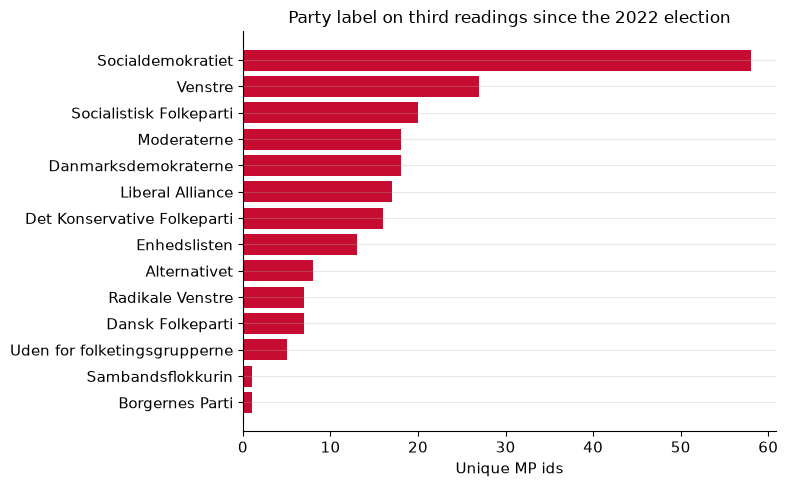

In [17]:
# Parties that had not yet entered the Folketing on these dates.
ENTRY = {
    "Alternativet": pd.Timestamp("2015-06-18"),
    "Nye Borgerlige": pd.Timestamp("2019-06-05"),
    "Danmarksdemokraterne": pd.Timestamp("2022-11-01"),
    "Moderaterne": pd.Timestamp("2022-11-01"),
}
warnings = []
for party, entry in ENTRY.items():
    early = df_raw[(df_raw["party"] == party) & (df_raw["dato"] < entry)]
    if early.empty:
        continue
    warnings.append({
        "party": party,
        "entered_folketing": entry.date().isoformat(),
        "earliest_labeled_vote": early["dato"].min().date().isoformat(),
        "vote_rows_before_entry": len(early),
        "mps_before_entry": early["aktørid"].nunique(),
    })
print("Party labels on votes dated before that party entered the Folketing")
display(pd.DataFrame(warnings))

recent_ids = set(df_dk.loc[df_dk["dato"] >= pd.Timestamp("2022-11-01"), "afstemningid"])
recent = df_raw[df_raw["afstemningid"].isin(recent_ids)]
recent_mps = (
    recent.groupby("party")["aktørid"]
    .nunique()
    .sort_values(ascending=True)
)
print(
    f"Unique MP ids by stored party, on third readings from 2022-11-01 "
    f"({recent['afstemningid'].nunique():,} votes present in the party files)"
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(recent_mps.index, recent_mps.to_numpy(), color=DK_COLOR)
ax.set_xlabel("Unique MP ids")
ax.set_title("Party label on third readings since the 2022 election")
fig.tight_layout()
plt.show()


## 9. What this means for the comparison

Use the date of the vote when lining the two parliaments up. Folder `2014-2019` still contains votes from the second half of 2019, and the Danish file does not reach back into EP7.

Compare texts with the unit each file actually stores. A Danish row is the third reading of one bill. A VoteWatch row is one roll call among many, often a resolution. Its `procedure_reference` is usually empty, and when it is filled in it is a reading mark rather than a dossier id. A later EP row is a main vote, usually one per dossier. Annual counts become comparable only after that 2019 cutoff: both sides then produce a few hundred votes a year.

Keep both title problems in view when reading embedding similarities. Danish English titles are long names of the law being amended, and the translation often drops the parenthesis that distinguishes one amendment from another, so different bills share one English string. EP titles are short labels, and the same label is reused. Subject labels exist for the Danish bills and show a domestic agenda; 40 bills are tagged `EU`. There is no parallel subject field on the EP votes in these extracts.

Read the For-shares as properties of the sample. Third readings and EP main votes both produce many For ballots. VoteWatch-era Danish MEP rows include a much larger share of Against and Did not vote, because those files keep the full roll-call record.

Leave historical party splits out of the comparison until the Folketing party column is rebuilt as party-at-the-time. The current raw files label 2011 votes with parties that entered parliament in 2022.
